In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
DATA_DIR = '../data/raw'

In [2]:
df = pd.read_csv(f'{DATA_DIR}/heart.csv')
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head()

Shape: (918, 12)
Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.info()
print("\nDescriptive stats:")
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

Descriptive stats:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing: {df.isnull().sum().sum()}")

Missing values per column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total missing: 0


In [5]:
# Cholesterol and RestingBP can have 0 as hidden missing (physiologically impossible)
print("Zero value counts:")
for col in ['RestingBP', 'Cholesterol']:
    zeros = (df[col] == 0).sum()
    pct = zeros / len(df) * 100
    print(f"  {col:15s}: {zeros:3d} zeros ({pct:.1f}%)")

Zero value counts:
  RestingBP      :   1 zeros (0.1%)
  Cholesterol    : 172 zeros (18.7%)


Class distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64

Percentages:
HeartDisease
1    55.34
0    44.66
Name: count, dtype: float64


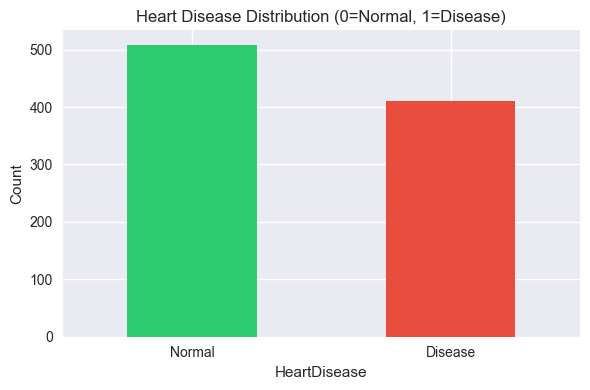

In [6]:
target_counts = df['HeartDisease'].value_counts()
print("Class distribution:")
print(target_counts)
print(f"\nPercentages:")
print((target_counts / len(df) * 100).round(2))

plt.figure(figsize=(6, 4))
target_counts.plot(kind='bar', color=['#2ecc71', '#e74c3c'])
plt.title('Heart Disease Distribution (0=Normal, 1=Disease)')
plt.xticks([0, 1], ['Normal', 'Disease'], rotation=0)
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../reports/eda_heart_target.png', dpi=150)
plt.show()

In [7]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


Sex:
Sex
M    725
F    193
Name: count, dtype: int64

ChestPainType:
ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

RestingECG:
RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

ExerciseAngina:
ExerciseAngina
N    547
Y    371
Name: count, dtype: int64

ST_Slope:
ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64


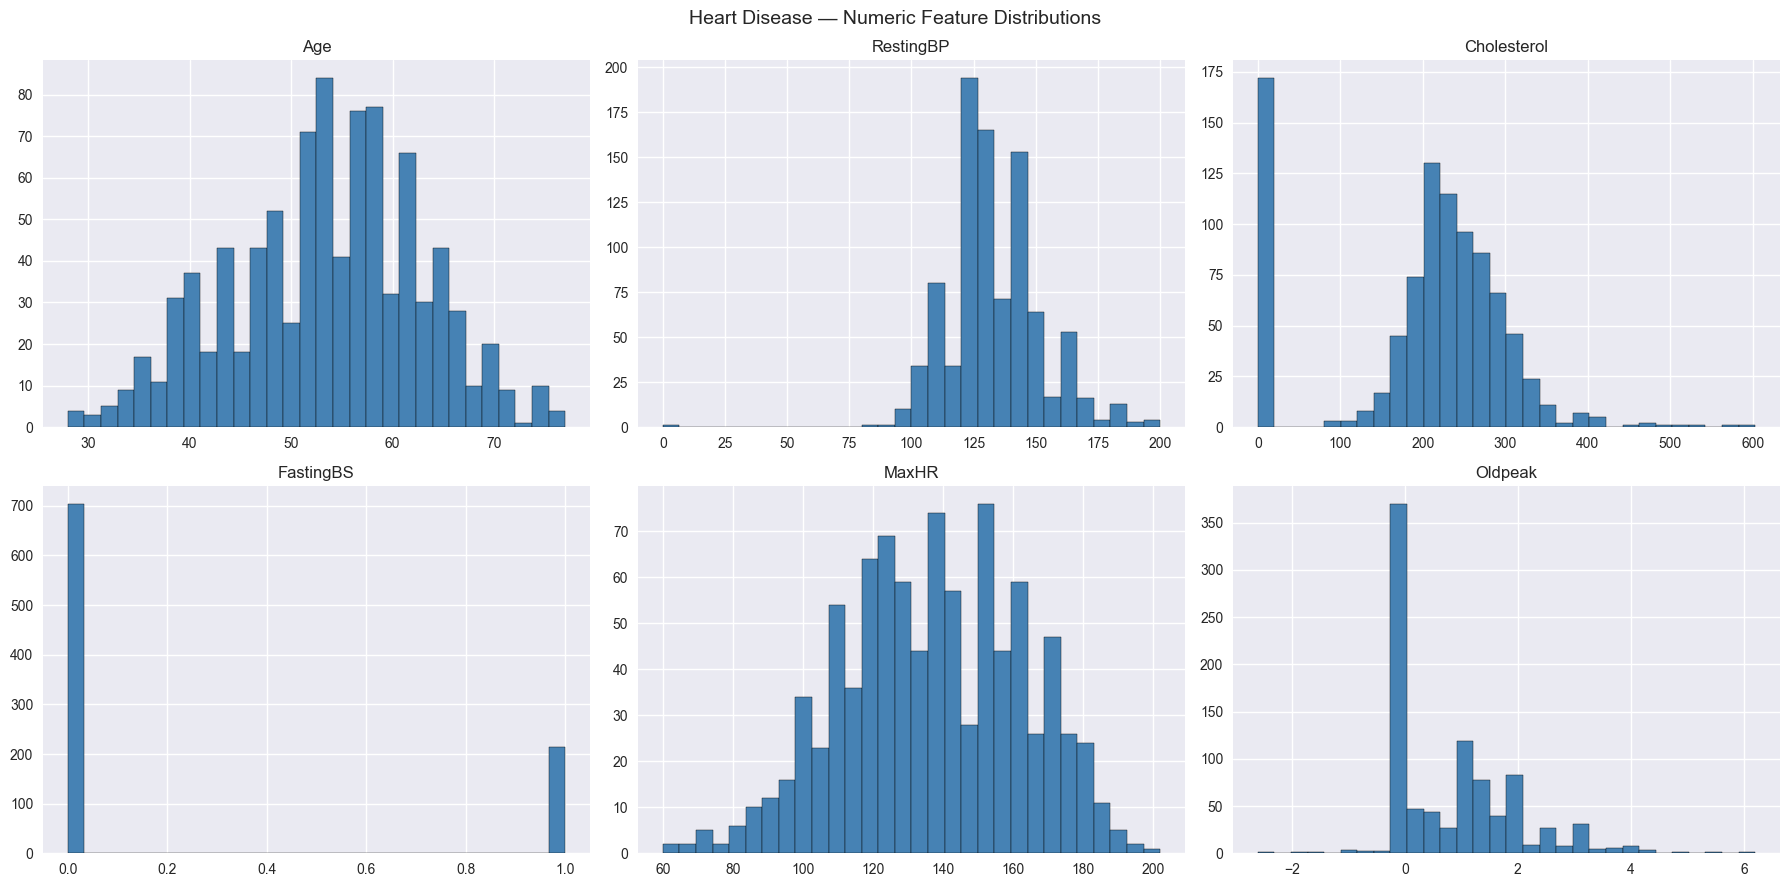

In [8]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flatten(), num_cols):
    df[col].hist(ax=ax, bins=30, color='steelblue', edgecolor='black')
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Heart Disease — Numeric Feature Distributions', fontsize=14)
plt.tight_layout()
plt.savefig('../reports/eda_heart_distributions.png', dpi=150)
plt.show()

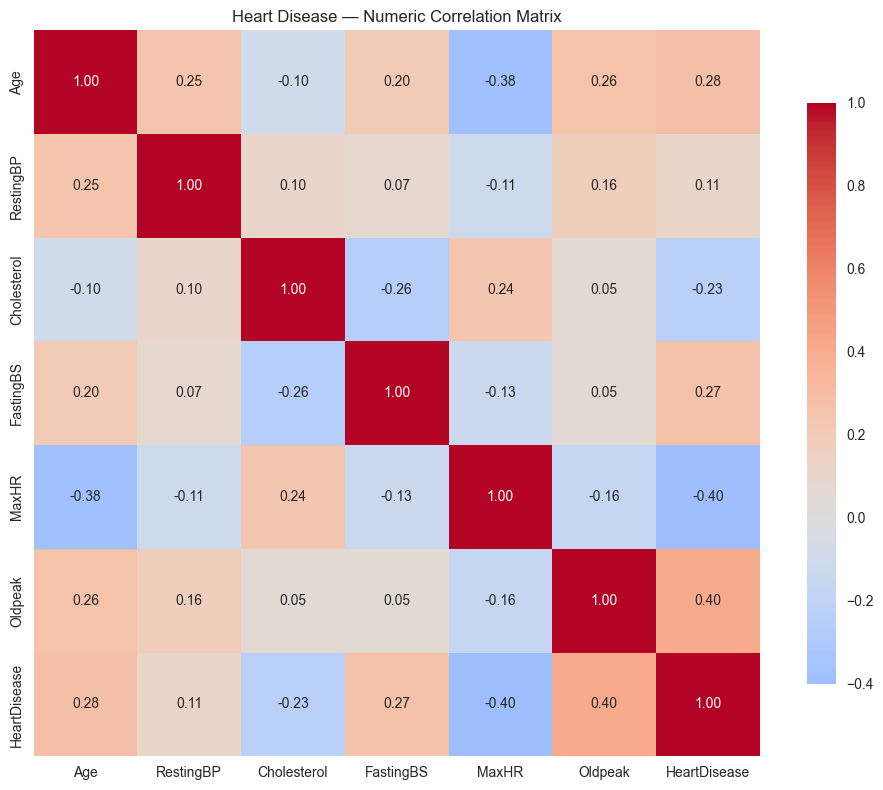


Correlations with HeartDisease (numeric only):
Oldpeak        0.403951
Age            0.282039
FastingBS      0.267291
RestingBP      0.107589
Cholesterol   -0.232741
MaxHR         -0.400421
Name: HeartDisease, dtype: float64


In [9]:
plt.figure(figsize=(10, 8))
corr = df[num_cols + ['HeartDisease']].corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Heart Disease — Numeric Correlation Matrix')
plt.tight_layout()
plt.savefig('../reports/eda_heart_correlation.png', dpi=150)
plt.show()

print("\nCorrelations with HeartDisease (numeric only):")
print(corr['HeartDisease'].drop('HeartDisease').sort_values(ascending=False))

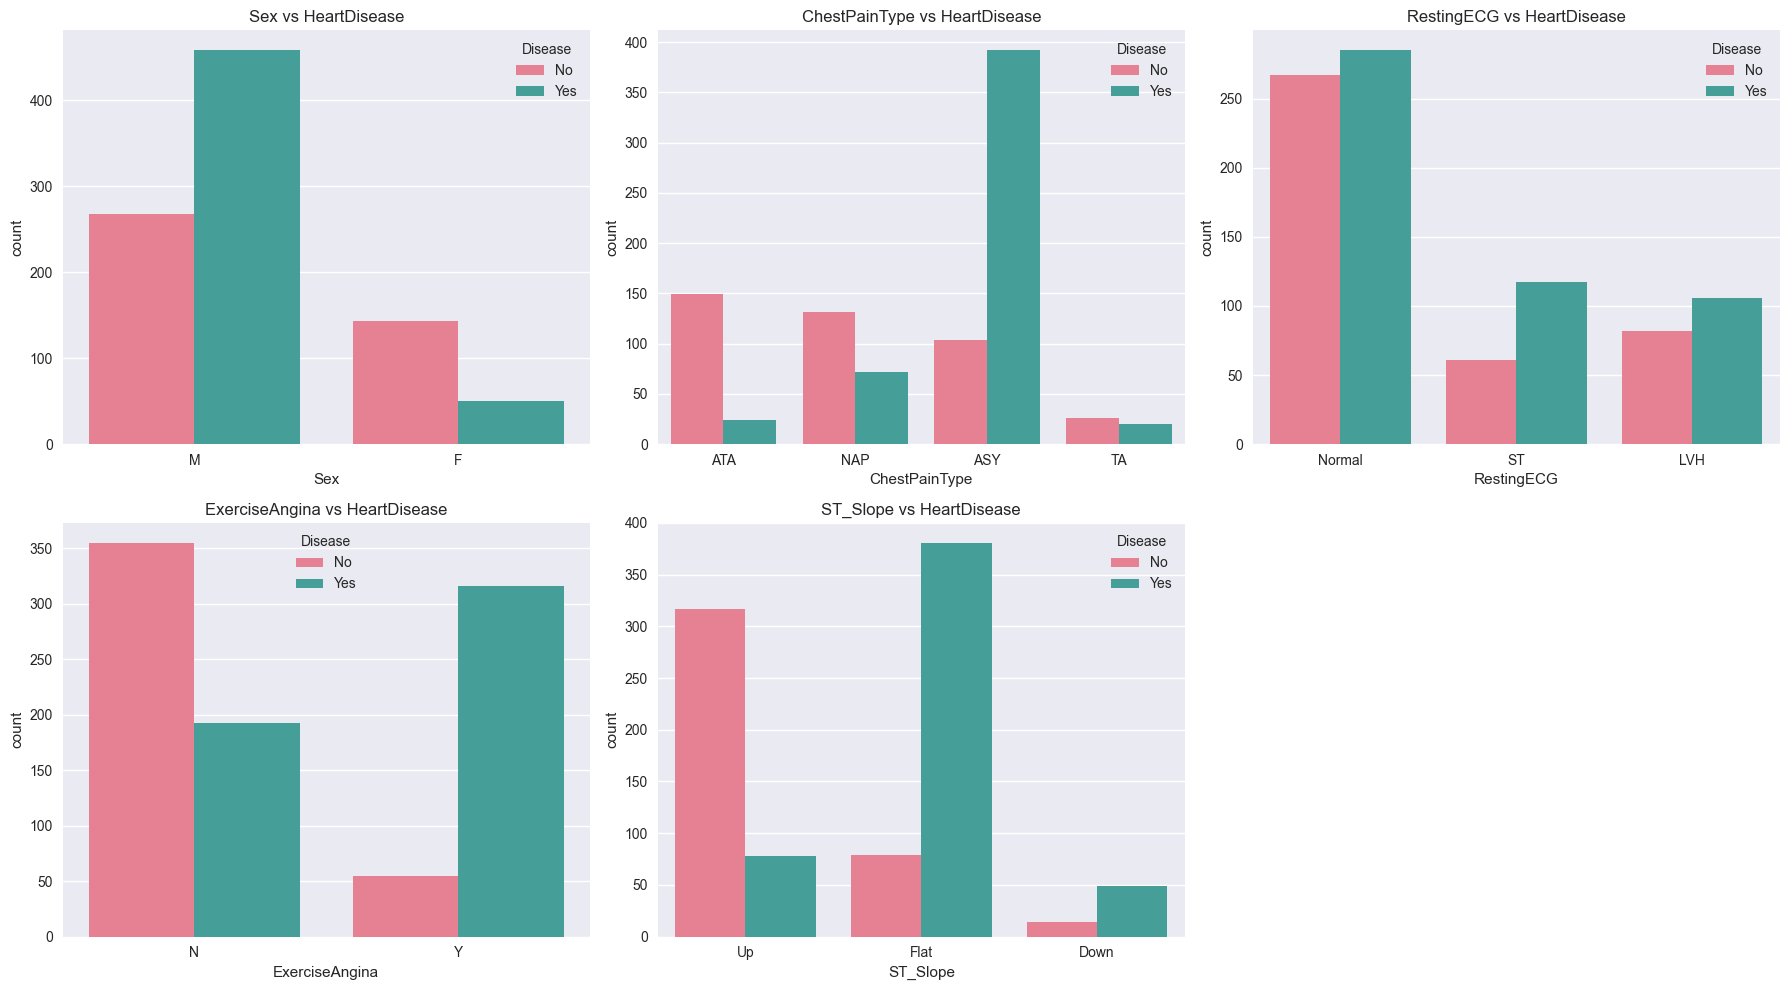

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=df, x=col, hue='HeartDisease', ax=ax, palette='husl')
    ax.set_title(f'{col} vs HeartDisease')
    ax.legend(title='Disease', labels=['No', 'Yes'])
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.savefig('../reports/eda_heart_categorical.png', dpi=150)
plt.show()

In [11]:
import os
os.makedirs('../data/processed', exist_ok=True)

df_clean = df.copy()

# 1. Replace 0s with NaN in physiologically impossible fields
df_clean['Cholesterol'] = df_clean['Cholesterol'].replace(0, np.nan)
df_clean['RestingBP'] = df_clean['RestingBP'].replace(0, np.nan)

# 2. Binary categoricals → 0/1
df_clean['Sex'] = df_clean['Sex'].map({'M': 1, 'F': 0})
df_clean['ExerciseAngina'] = df_clean['ExerciseAngina'].map({'Y': 1, 'N': 0})

# 3. Multi-class categoricals → one-hot
df_clean = pd.get_dummies(
    df_clean,
    columns=['ChestPainType', 'RestingECG', 'ST_Slope'],
    drop_first=True,
    dtype=int
)

print(f"Final shape after encoding: {df_clean.shape}")
print(f"Columns: {df_clean.columns.tolist()}")
print(f"\nNaN values remaining (will impute in model notebook):")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# Save
df_clean.to_csv('../data/processed/heart_clean.csv', index=False)
print("\n✅ Saved: data/processed/heart_clean.csv")

Final shape after encoding: (918, 16)
Columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']

NaN values remaining (will impute in model notebook):
RestingBP        1
Cholesterol    172
dtype: int64

✅ Saved: data/processed/heart_clean.csv


## 📊 EDA Summary — Heart Failure Prediction (918 rows)

### Dataset Overview
- **Rows:** 918 | **Features:** 11 + 1 target
- **Source:** fedesoriano compilation of 5 UCI datasets (Cleveland, Hungarian, Switzerland, Long Beach VA, Stalog)
- **Target:** `HeartDisease` (1 = disease, 0 = normal) — already binary ✅
- **Classes:** 508 disease (55.3%) / 410 normal (44.7%) — **mildly balanced**

### Key Findings
1. **No missing values** in the raw CSV — but `Cholesterol` has **172 zeros (18.7%)** and `RestingBP` has **1 zero** → physiologically impossible → must treat as hidden missing
2. **Categoricals present:** `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`
3. **Strongest numeric predictors:** `MaxHR` (r=-0.40), `Oldpeak` (r=+0.40), `Age` (r=+0.28)
4. **`ChestPainType=ASY`** dominates the disease group (asymptomatic presentation is high-risk)
5. **`ST_Slope=Flat/Down`** and **`ExerciseAngina=Y`** strongly associated with disease

### Preprocessing Decisions
- Replace 0 → NaN in `Cholesterol` and `RestingBP` (impute in Phase 2)
- Encode `Sex` (M=1, F=0), `ExerciseAngina` (Y=1, N=0)
- One-hot encode `ChestPainType`, `RestingECG`, `ST_Slope` (drop_first=True)
- **No SMOTE needed** (classes already close to balanced)
- Plan: StandardScaler for continuous features
